In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import (
    RunResults,
    plot_erasure_trajectory,
    plot_remaining_key_values,
    plot_mosaic_series,
    get_fwd_fwd_context_tokens
)

---

Analogs of fig. 5 for the `who_is` setting

In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR  = REPO_ROOT / 'figures/generated/supplementary/figure_s6_s7'
SAVE_FIGURES = True
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS = RunResults(results_root=RESULTS_ROOT)

In [3]:
# LOAD AN ERASURE TRAJECTORY

MODEL_PRESET  = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_yes_no'
# PROMPT_PRESET = 'ABC_company_structure'

TRAJECTORY = RESULTS.load_erasure_trajectory(
    model_preset=MODEL_PRESET, 
    prompt_preset=PROMPT_PRESET
)

In [4]:
# RETRIEVE INFO ABOUT "KEY POINTS" IN THE TRAJECTORY

CONDITION_NAMES = (
    "FIDELITY_50",
    "FIDELITY_80",
    "FIDELITY_95",
    "FIDELITY_95_SITES_X2",
)

from cognitive_maps_in_llms.experiments.utils_erasure import load_erasure_conditions
conditions = load_erasure_conditions(TRAJECTORY.directory, CONDITION_NAMES)

def phase_at_iteration(iteration):
    next_round = iteration + 1
    n_erased = (
        (TRAJECTORY.key_erasure_round_tli == next_round).sum()
        + (TRAJECTORY.value_erasure_round_tli == next_round).sum()
    )
    return "fine" if n_erased == 1 else "coarse"

for condition_name in CONDITION_NAMES:
    condition = conditions[condition_name]
    iteration = condition.iteration

    score = TRAJECTORY.score_by_iteration[iteration]
    fidelity = (
        (score - TRAJECTORY.fully_erased_score)
        / (TRAJECTORY.initial_score - TRAJECTORY.fully_erased_score)
    )
    phase = phase_at_iteration(iteration)

    print(f'"{condition_name}":')
    print(f'Iteration: {iteration} (during "{phase}" phase)')
    print(f"Fidelity: {fidelity:.3f}")
    print(f"{condition.n_keys} remaining keys; {condition.n_values} remaining values")
    print()

FINE_START_ITERATION = next(
    iteration
    for iteration in range(len(TRAJECTORY.score_by_iteration))
    if phase_at_iteration(iteration) == "fine"
)

score = TRAJECTORY.score_by_iteration[FINE_START_ITERATION]
fidelity = (
    (score - TRAJECTORY.fully_erased_score)
    / (TRAJECTORY.initial_score - TRAJECTORY.fully_erased_score)
)
key_mask, value_mask = TRAJECTORY.masks_at_iteration(FINE_START_ITERATION)

print('"COARSE_TO_FINE":')
print(f'Iteration: {FINE_START_ITERATION} (start of "fine" phase)')
print(f"Fidelity: {fidelity:.3f}")
print(f"{key_mask.sum()} remaining keys; {value_mask.sum()} remaining values")
print()

"FIDELITY_50":
Iteration: 143 (during "fine" phase)
Fidelity: 0.545
54 remaining keys; 0 remaining values

"FIDELITY_80":
Iteration: 129 (during "fine" phase)
Fidelity: 0.836
68 remaining keys; 0 remaining values

"FIDELITY_95":
Iteration: 106 (during "fine" phase)
Fidelity: 0.962
87 remaining keys; 4 remaining values

"FIDELITY_95_SITES_X2":
Iteration: 37 (during "coarse" phase)
Fidelity: 0.974
176 remaining keys; 20 remaining values

"COARSE_TO_FINE":
Iteration: 39 (start of "fine" phase)
Fidelity: 0.969
142 remaining keys; 16 remaining values



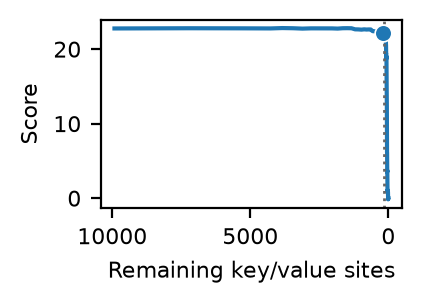

In [5]:
# PLOT AN ERASURE TRAJECTORY...

plot = plot_erasure_trajectory(
    TRAJECTORY,
    x_axis="remaining_sites",
    transition_iteration=FINE_START_ITERATION,
    marked_iterations={
        "FIDELITY_95_SITES_X2":
            conditions["FIDELITY_95_SITES_X2"].iteration,
    },
)

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'erasure_trajectory_zoomed_out.svg')
plt.close(plot.fig)

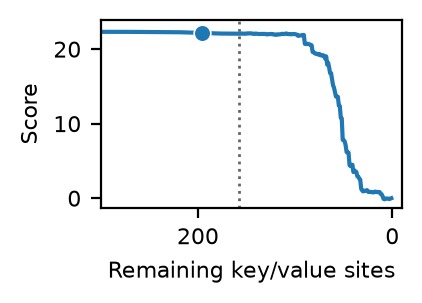

In [6]:
# ...AND A ZOOMED IN VERSION

plot.ax.set_xlim((300, -10))

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'erasure_trajectory_zoomed_in.svg')
plt.close(plot.fig)

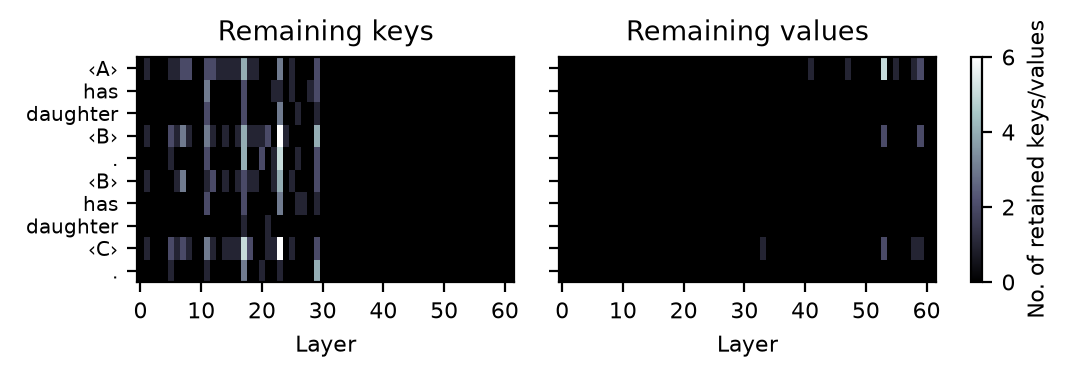

In [7]:
plot = plot_remaining_key_values(
    TRAJECTORY,
    iteration=conditions["FIDELITY_95_SITES_X2"].iteration,
    token_labels=get_fwd_fwd_context_tokens(MODEL_PRESET, PROMPT_PRESET),
)
# Note that context-token labels require local tokenizer files under LNT_MODELS_DIR for the selected model preset

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'key_value_distribution.svg')
plt.close(plot.fig)


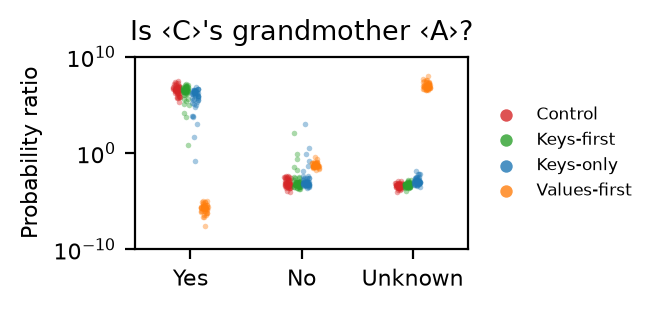

In [8]:
# FIGURE 5A

MODEL_PRESET  = 'gemma-27b'
# MODEL_PRESET = 'llama-70b'
# MODEL_PRESET  = 'qwen-32b'

# ----------------------------------------------
PROMPT_PRESET = 'ABC_family_tree_yes_no'
EXPERIMENT = 'exp_5a_bottleneck'
QUERY = 'C --grandmother--> A?'

control = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'CTRL'
)
keys_first = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'K_THEN_V'
)
keys_only = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'K_ONLY'
)
values_first = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'V_THEN_K'
)

plot = plot_mosaic_series(
    {
        "Control": control, 
        "Keys-first": keys_first, 
        "Keys-only": keys_only,
        "Values-first": values_first, 
    },
    value_kind = "probability_ratio",
    colors = ("tab:red", "tab:green", "tab:blue", "tab:orange"),
    jitter = 0.03,
    legend=True,
    title="Is ‹C›'s grandmother ‹A›?"
)
# plot.ax.set_ylim((1e-17, 1e17))

legend = plot.ax.get_legend()
legend.set_loc("center left")
legend.set_bbox_to_anchor((1.02, 0.5))

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'fig_5_bottlenecks.svg')
plt.close(plot.fig)

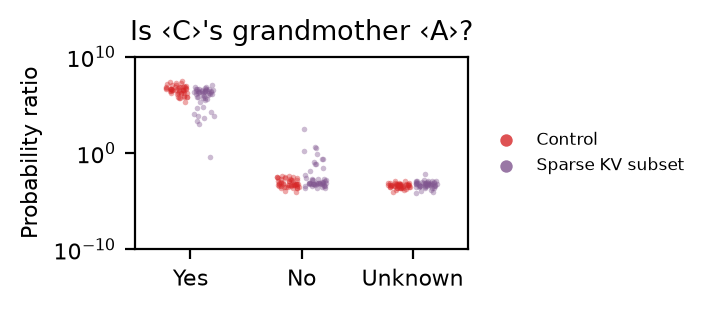

In [9]:
# FIGURE 5B

MODEL_PRESET  = 'gemma-27b'
# MODEL_PRESET = 'llama-70b'
# MODEL_PRESET  = 'qwen-32b'

# ----------------------------------------------
PROMPT_PRESET = 'ABC_family_tree_yes_no'
EXPERIMENT = 'exp_5b_sparse_mosaic'
QUERY = 'C --grandmother--> A?'

control = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'REPLACE_ALL'
)
sparse_mosaic = RESULTS.load_series(
    model_preset = MODEL_PRESET,
    prompt_preset = PROMPT_PRESET,
    experiment = EXPERIMENT,
    query = QUERY,
    condition = 'FIDELITY_95_SITES_X2'
)

plot = plot_mosaic_series(
    {"Control": control, "Sparse KV subset": sparse_mosaic},
    value_kind = "probability_ratio",
    legend=True,
    title="Is ‹C›'s grandmother ‹A›?"
)
legend = plot.ax.get_legend()
legend.set_loc("center left")
legend.set_bbox_to_anchor((1.02, 0.5))

display(plot.fig)
if SAVE_FIGURES:
    plot.save(FIGURES_DIR / 'fig_5_sparse_mosaic.svg')
plt.close(plot.fig)

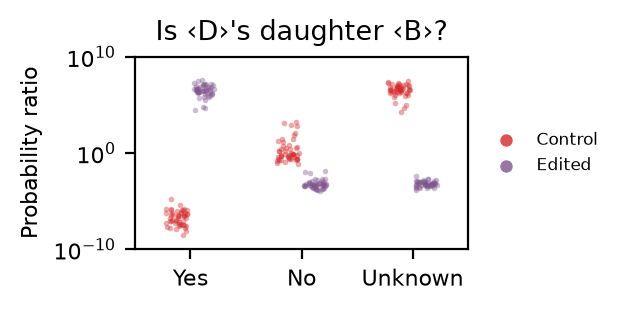

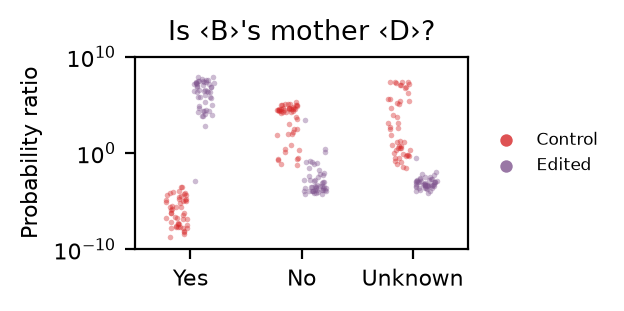

In [10]:
# FIGURE 5C, PANEL 2

MODEL_PRESET  = 'gemma-27b'
# MODEL_PRESET = 'llama-70b'
# MODEL_PRESET  = 'qwen-32b'

# ----------------------------------------------
PROMPT_PRESET = 'ABC_family_tree_yes_no'
EXPERIMENT = 'exp_5c_editing'
QUERY = 'D --daughter--> B?'

def plot_figure_5_query(query: str, title: str, filename: str):
    control = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        condition = 'FIDELITY_95_SITES_X2',
        editing_locs = 'NONE'
    )
    mosaic = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        condition = 'FIDELITY_95_SITES_X2',
        editing_locs = 'A_KEYS'
    )

    plot = plot_mosaic_series(
        {'Control': control, 'Edited': mosaic},
        value_kind='probability_ratio',
        title=title,
        legend=True,
    )
    legend = plot.ax.get_legend()
    legend.set_loc("center left")
    legend.set_bbox_to_anchor((1.02, 0.5))
    
    if SAVE_FIGURES:
        plot.save(FIGURES_DIR / filename)
    return plot


FIGURE_SPECS = (
    ('D --daughter--> B?', "Is ‹D›'s daughter ‹B›?", 'fig_5_is_Ds_daughter_B.svg'),
    ('B --mother--> D?', "Is ‹B›'s mother ‹D›?", 'fig_5_is_Bs_mother_D.svg'),
)

for query, title, filename in FIGURE_SPECS:
    plot = plot_figure_5_query(query, title, filename)
    display(plot.fig)
    plt.close(plot.fig)


---

Analogs of fig. 2 for the `who_is` setting

In [11]:
# HELPER FOR FIGURE 2 PLOT

MODEL_PRESET = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_who_is'
EXPERIMENT = 'exp_2_separability'
CONTROL_PATCH_LOCATION = 'CTRL'
MOSAIC_PATCH_LOCATION = 'B1'
RESULTS = RunResults(results_root=RESULTS_ROOT)

def plot_figure_2_query(query: str, title: str, filename: str):
    control = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        patch_location=CONTROL_PATCH_LOCATION,
    )
    mosaic = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        patch_location=MOSAIC_PATCH_LOCATION,
    )

    plot = plot_mosaic_series(
        {'Control': control, 'Mosaic': mosaic},
        value_kind='probability_ratio',
        title=title,
        legend=False,
    )
    if SAVE_FIGURES:
        plot.save(FIGURES_DIR / filename)
    return plot


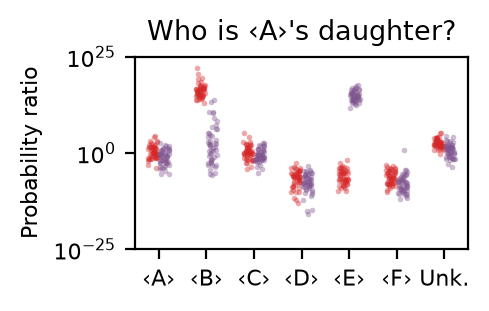

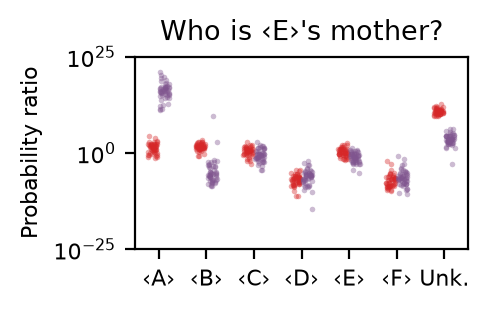

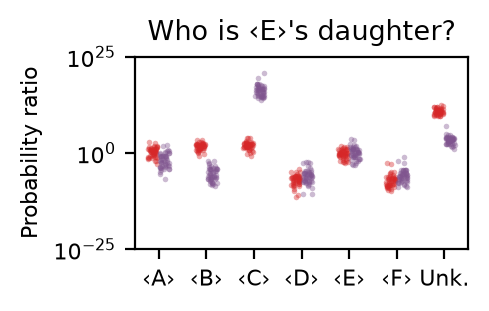

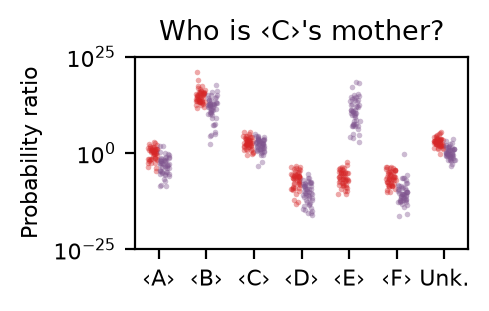

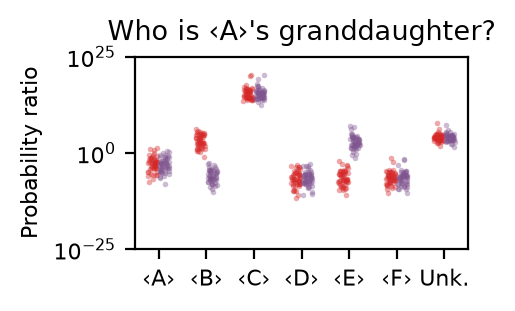

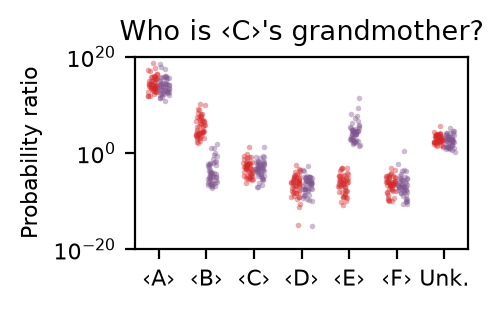

In [12]:
FIGURE_SPECS = (
    ('A --daughter--> ?', "Who is ‹A›'s daughter?", 'fig_2_who_is_As_daughter.svg'),
    ('E --mother--> ?', "Who is ‹E›'s mother?", 'fig_2_who_is_Bs_mother.svg'),
    ('E --daughter--> ?', "Who is ‹E›'s daughter?", 'fig_2_who_is_Bs_daughter.svg'),
    ('C --mother--> ?', "Who is ‹C›'s mother?", 'fig_2_who_is_Cs_mother.svg'),
    ('A --granddaughter--> ?', "Who is ‹A›'s granddaughter?", 'fig_2_who_is_As_granddaughter.svg'),
    ('C --grandmother--> ?', "Who is ‹C›'s grandmother?", 'fig_2_who_is_Cs_grandmother.svg'),
)

for query, title, filename in FIGURE_SPECS:
    plot = plot_figure_2_query(query, title, filename)
    display(plot.fig)
    plt.close(plot.fig)


---

Analogs of fig. 4 for the `who_is` setting

In [13]:
# HELPER FOR FIGURE FOUR PLOT

MODEL_PRESET = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_who_is'
EXPERIMENT = 'exp_4_retrospective_prospective'
STRUCTURE_PAIR = {
    'donor': 'A --rev--> B --fwd--> C',
    'control': 'A --fwd--> B --fwd--> C',
}
CONTROL_CONDITION = 'CTRL'
MOSAIC_CONDITION = 'ENTITY_RELATION_SPAN'
RESULTS = RunResults(results_root=RESULTS_ROOT)

def plot_figure_4_query(query: str, title: str, filename: str):
    control = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        structure_pair=STRUCTURE_PAIR,
        condition=CONTROL_CONDITION,
    )
    mosaic = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        structure_pair=STRUCTURE_PAIR,
        condition=MOSAIC_CONDITION,
    )

    plot = plot_mosaic_series(
        {'Control': control, 'Mosaic': mosaic},
        value_kind='probability_ratio',
        title=title,
        legend=False,
    )
    if SAVE_FIGURES:
        plot.save(FIGURES_DIR / filename)
    return plot


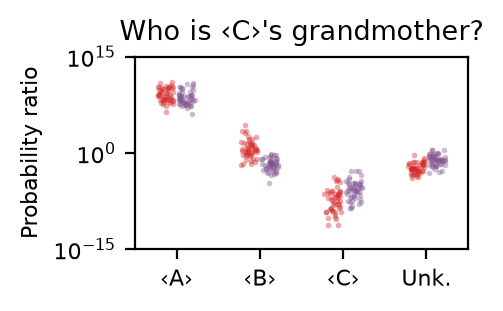

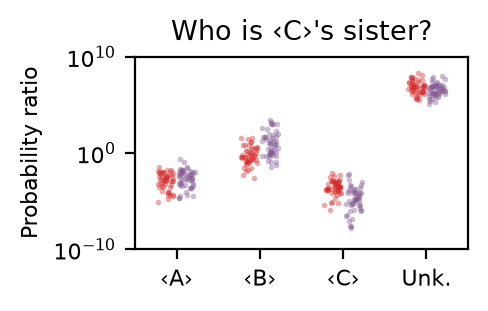

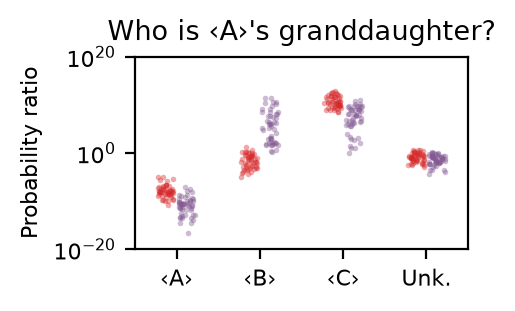

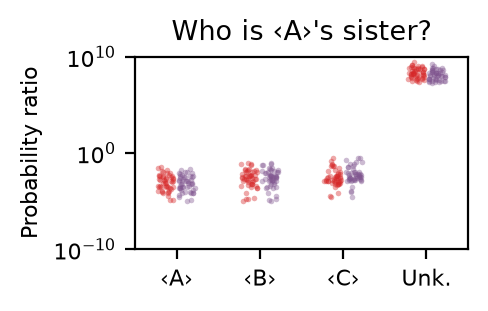

In [14]:
FIGURE_SPECS = (
    ('C --grandmother--> ?', "Who is ‹C›'s grandmother?", 'fig_4_who_is_Cs_grandmother_prospective.svg'),
    ('C --sister--> ?', "Who is ‹C›'s sister?", 'fig_4_who_is_Cs_sister_prospective.svg'),
    ('A --granddaughter--> ?', "Who is ‹A›'s granddaughter?", 'fig_4_who_is_As_granddaughter_prospective.svg'),
    ('A --sister--> ?', "Who is ‹A›'s sister?", 'fig_4_who_is_As_sister_prospective.svg'),
)

for query, title, filename in FIGURE_SPECS:
    plot = plot_figure_4_query(query, title, filename)
    display(plot.fig)
    plt.close(plot.fig)
